Sampling rate bench testing 

we will measure for each accelerometer, gyroscope and ppg: 
1. Actual Sampling Rate (Hz)
2. Number of gaps 
3. Esitmated missing Samples

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd

folder = Path(
    "/Users/jadechng/Desktop/HomeStretch/HomeStretchRepo/Data/new_watch"
)

sensor_names = {
    1: "Accelerometer",
    2: "Gyroscope",
    4: "PPG 4",
    5: "PPG 5",
    6: "PPG 6",
    7: "PPG 7",
}

sensor_results = []
dropout_results = []

for file in sorted(folder.glob("*.csv")):
    df = pd.read_csv(file)

    # Sequence numbers are shared across sensors, so check them
    # BEFORE separating the data by sensor.
    for session_id, session in df.groupby("protocol_session_id", sort=False):
        sequence = session["sequence"].to_numpy(dtype=np.int64)
        steps = np.diff(sequence) % 65536  # Handles 16-bit counter wraparound

        # Don't mistake duplicates or backward jumps for missing records.
        sequence_ok = not np.any((steps == 0) | (steps >= 32768))
        missing = int(np.sum(steps - 1)) if sequence_ok else np.nan

        dropout_results.append({
            "Recording": file.stem,
            "Session": session_id,
            "Records received": len(session),
            "Missing records": missing,
            "Missing records (%)": (
                100 * missing / (len(session) + missing)
                if sequence_ok else np.nan
            ),
            "Sequence check": "OK" if sequence_ok else "Needs review",
        })

        for sensor_type, data in session.groupby("type", sort=True):
            # Preserve original order so timestamp problems remain visible.
            timestamps = data["watch_timestamp_ms"].to_numpy(dtype=float)
            intervals = np.diff(timestamps)  # milliseconds

            timestamps_ok = (
                len(intervals) > 0
                and np.all(np.isfinite(timestamps))
                and np.all(intervals > 0)
            )

            duration = (
                (timestamps[-1] - timestamps[0]) / 1000
                if timestamps_ok else np.nan
            )
            typical_interval = (
                np.median(intervals) if timestamps_ok else np.nan
            )

            sensor_results.append({
                "Recording": file.stem,
                "Session": session_id,
                "Sensor": sensor_names.get(sensor_type, f"Type {sensor_type}"),
                "Samples": len(data),
                "Duration (s)": duration,
                "Recorded rate (Hz)": (
                    (len(data) - 1) / duration
                    if timestamps_ok else np.nan
                ),
                "Long gaps": (
                    int(np.sum(intervals > 1.5 * typical_interval))
                    if timestamps_ok else np.nan
                ),
                "Largest gap (ms)": (
                    intervals.max() if timestamps_ok else np.nan
                ),
                "Invalid readings (%)": (
                    100 * data["validity"].ne(1).mean()
                ),
                "Timestamp check": "OK" if timestamps_ok else "Needs review",
            })

sampling_summary = pd.DataFrame(sensor_results)
dropout_summary = pd.DataFrame(dropout_results)

print("SAMPLING RATE — per sensor")
display(sampling_summary.round(2))

print("\nMISSING RECORDS — across all sensors")
display(dropout_summary.round(2))

SAMPLING RATE — per sensor


,Recording,Session,Sensor,Samples,Duration (s),Recorded rate (Hz),Long gaps,Largest gap (ms),Invalid readings (%),Timestamp check
0,VitalWave-v0_Bicep-curls-1_Jade_2026-10-22_193...,2501154417,Accelerometer,628,25.09,24.99,0,58.0,0.00,OK
1,VitalWave-v0_Bicep-curls-1_Jade_2026-10-22_193...,2501154417,Gyroscope,628,25.09,24.99,0,58.0,0.00,OK
2,VitalWave-v0_Bicep-curls-1_Jade_2026-10-22_193...,2501154417,PPG 4,1259,25.16,50.00,0,20.0,0.00,OK
3,VitalWave-v0_Bicep-curls-1_Jade_2026-10-22_193...,2501154417,PPG 5,1259,25.16,50.00,0,20.0,0.00,OK
4,VitalWave-v0_Bicep-curls-1_Jade_2026-10-22_193...,2501154417,PPG 6,1259,25.16,50.00,0,20.0,0.00,OK
5,VitalWave-v0_Bicep-curls-1_Jade_2026-10-22_193...,2501154417,PPG 7,1259,25.16,50.00,0,20.0,0.00,OK
6,VitalWave-v0_Bicep-curls-2--3rd-and-4th-is-aty...,3966413804,Accelerometer,900,17.98,50.00,48,38.0,3.22,OK
7,VitalWave-v0_Bicep-curls-2--3rd-and-4th-is-aty...,3966413804,Gyroscope,900,17.98,50.00,48,38.0,3.22,OK
8,VitalWave-v0_Bicep-curls-2--3rd-and-4th-is-aty...,3966413804,PPG 4,902,18.02,50.00,0,20.0,0.00,OK
9,VitalWave-v0_Bicep-curls-2--3rd-and-4th-is-aty...,3966413804,PPG 5,902,18.02,50.00,0,20.0,0.00,OK



MISSING RECORDS — across all sensors


,Recording,Session,Records received,Missing records,Missing records (%),Sequence check
0,VitalWave-v0_Bicep-curls-1_Jade_2026-10-22_193...,2501154417,6292,0,0.0,OK
1,VitalWave-v0_Bicep-curls-2--3rd-and-4th-is-aty...,3966413804,5408,0,0.0,OK
2,VitalWave-v0_Bicep-curls-2_baseline_Jade_2026-...,893735869,4726,0,0.0,OK
3,VitalWave-v0_Bicep-curls-2nd-and-3rd-is-atypic...,700396372,5558,0,0.0,OK
4,VitalWave-v0_Jessica-4th-rep-onwards-is-off-ax...,1165153334,4035,0,0.0,OK
5,VitalWave-v0_Jessica-Calibration-baseline_righ...,351605173,3901,0,0.0,OK
6,VitalWave-v0_Jessica-calibration-left-arm_jess...,1219550,3777,0,0.0,OK
7,VitalWave-v0_Jessica-left-weight-on-the-left-o...,165184790,5667,0,0.0,OK
8,VitalWave-v0_Jessica-left-weight-on-the-left-o...,983517388,7230,0,0.0,OK
9,VitalWave-v0_Jessica-with-arm-held-down-4th-on...,2342203097,5853,0,0.0,OK


In [2]:
# Keep accelerometer, gyroscope, and green PPG only
selected = sampling_summary[
    sampling_summary["Sensor"].isin(
        ["Accelerometer", "Gyroscope", "PPG 6"]
    )
].copy()

selected["Sensor"] = selected["Sensor"].replace({"PPG 6": "Green PPG"})

# Each recording/session gets equal weight in these averages.
average_summary = (
    selected.groupby("Sensor", sort=False)
    .agg(
        Recordings=("Recording", "count"),
        Average_rate_Hz=("Recorded rate (Hz)", "mean"),
        Rate_SD_Hz=("Recorded rate (Hz)", "std"),
        Average_long_gaps_per_recording=("Long gaps", "mean"),
        Average_invalid_percent=("Invalid readings (%)", "mean"),
    )
    .reset_index()
)

display(average_summary.round(2))

# Missing records must be checked across ALL sensor types,
# because they share one sequence counter.
if dropout_summary["Sequence check"].eq("OK").all():
    missing = dropout_summary["Missing records"].sum()
    received = dropout_summary["Records received"].sum()
    dropout_percent = 100 * missing / (received + missing)

    print(f"Overall missing-record rate: {dropout_percent:.2f}%")
else:
    print("Sequence issues need review before calculating overall dropout.")

,Sensor,Recordings,Average_rate_Hz,Rate_SD_Hz,Average_long_gaps_per_recording,Average_invalid_percent
0,Accelerometer,10,45.0,10.54,73.2,3.31
1,Gyroscope,10,45.0,10.54,73.2,3.31
2,Green PPG,10,50.0,0.00,0.0,0.00


Overall missing-record rate: 0.00%


In [3]:
# Select sessions where BOTH IMU sensors recorded near 50 Hz.
# 49–51 Hz is our selection range, not a formal pass/fail standard.
imu = sampling_summary[
    sampling_summary["Sensor"].isin(["Accelerometer", "Gyroscope"])
]

rates = imu.pivot(
    index=["Recording", "Session"],
    columns="Sensor",
    values="Recorded rate (Hz)"
)

keep = rates.index[
    rates["Accelerometer"].between(49, 51)
    & rates["Gyroscope"].between(49, 51)
].to_frame(index=False)

# Keep the same sessions for IMU and green PPG.
selected = sampling_summary.merge(
    keep, on=["Recording", "Session"], how="inner"
)

selected = selected[
    selected["Sensor"].isin(["Accelerometer", "Gyroscope", "PPG 6"])
].copy()

selected["Sensor"] = selected["Sensor"].replace({"PPG 6": "Green PPG"})

summary_50hz = (
    selected.groupby("Sensor", sort=False)
    .agg(
        Recordings=("Recording", "count"),
        Average_rate_Hz=("Recorded rate (Hz)", "mean"),
        Rate_SD_Hz=("Recorded rate (Hz)", "std"),
        Average_long_gaps_per_recording=("Long gaps", "mean"),
        Average_invalid_percent=("Invalid readings (%)", "mean"),
    )
    .reset_index()
)

display(summary_50hz.round(2))

# Sequence-based dropout for those same sessions, across all sensor types.
dropouts = dropout_summary.merge(
    keep, on=["Recording", "Session"], how="inner"
)

if dropouts.empty:
    print("No recordings matched the 49–51 Hz selection.")
elif dropouts["Sequence check"].eq("OK").all():
    missing = dropouts["Missing records"].sum()
    received = dropouts["Records received"].sum()
    print(f"Missing-record rate: {100 * missing / (received + missing):.2f}%")
else:
    print("Sequence issues need review before calculating dropout.")

print(f"Included: {len(keep)} recording sessions")
print(f"Excluded: {len(rates) - len(keep)} recording sessions")

,Sensor,Recordings,Average_rate_Hz,Rate_SD_Hz,Average_long_gaps_per_recording,Average_invalid_percent
0,Accelerometer,8,50.0,0.0,91.5,4.13
1,Gyroscope,8,50.0,0.0,91.5,4.13
2,Green PPG,8,50.0,0.0,0.0,0.00


Missing-record rate: 0.00%
Included: 8 recording sessions
Excluded: 2 recording sessions


In [4]:
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display

FOLDER = Path(
    "/Users/jadechng/Desktop/HomeStretch/HomeStretchRepo/Data/new_watch"
)

SENSORS = {1: "Accelerometer", 2: "Gyroscope", 6: "Green PPG"}

rates = {sensor: [] for sensor in SENSORS}
intervals = {sensor: [] for sensor in SENSORS}
invalid_counts = {sensor: 0 for sensor in SENSORS}
sample_counts = {sensor: 0 for sensor in SENSORS}

included, excluded = [], []
total_received = 0
total_missing = 0

for file in sorted(FOLDER.glob("*.csv")):
    df = pd.read_csv(file)

    for session_id, session in df.groupby("protocol_session_id", sort=False):
        label = f"{file.name} | session {session_id}"
        measurements = {}

        for sensor_type in SENSORS:
            data = session[session["type"] == sensor_type]
            if len(data) < 2:
                continue

            # Original watch timestamps; do not sort or resample.
            t = data["watch_timestamp_ms"].to_numpy(dtype=float)
            dt = np.diff(t)

            if not np.all(np.isfinite(t)) or np.any(dt <= 0):
                raise ValueError(f"Check timestamps: {label}, type {sensor_type}")

            duration_s = (t[-1] - t[0]) / 1000
            measurements[sensor_type] = {
                "rate": (len(data) - 1) / duration_s,
                "intervals": dt,
                "samples": len(data),
                "invalid": int(data["validity"].ne(1).sum()),
            }

        # Select sessions where both IMU streams are near 50 Hz.
        # This selects a subset; it is NOT an overall system pass criterion.
        near_50 = all(
            sensor in measurements
            and 49 <= measurements[sensor]["rate"] <= 51
            for sensor in (1, 2)
        )

        if not near_50:
            excluded.append(label)
            continue

        # Sequence counter is shared across ALL sensor types.
        seq = session["sequence"].to_numpy(dtype=np.int64)
        steps = np.diff(seq) % 65536

        if np.any((steps == 0) | (steps >= 32768)):
            raise ValueError(f"Check sequence duplicates/reset/order: {label}")

        total_missing += int(np.sum(steps - 1))
        total_received += len(session)
        included.append(label)

        for sensor_type, values in measurements.items():
            rates[sensor_type].append(values["rate"])
            intervals[sensor_type].append(values["intervals"])
            sample_counts[sensor_type] += values["samples"]
            invalid_counts[sensor_type] += values["invalid"]

if not included:
    raise ValueError("No recording sessions matched the 49–51 Hz selection.")

rows = []

for sensor_type, name in SENSORS.items():
    if not intervals[sensor_type]:
        continue

    # Pool WITHIN-recording intervals only.
    # Never calculate a time interval between different recordings.
    dt = np.concatenate(intervals[sensor_type])

    rows.append({
        "Sensor": name,
        "Recordings": len(rates[sensor_type]),
        "Mean sampling frequency (Hz)": np.mean(rates[sensor_type]),
        "SD of inter-sample interval (ms)": np.std(dt, ddof=1),
        "Invalid readings (%)": (
            100 * invalid_counts[sensor_type] / sample_counts[sensor_type]
        ),
    })

bench_results = pd.DataFrame(rows)

dropout_pct = 100 * total_missing / (total_received + total_missing)

print("BENCH TEST — RECORDINGS MEASURED NEAR 50 Hz")
display(bench_results.round(3))

print(
    f"Dropped records across all sensor types: "
    f"{total_missing:,} / {total_received + total_missing:,} "
    f"({dropout_pct:.3f}%)"
)
print(f"\nIncluded recording sessions: {len(included)}")
print(f"Excluded recording sessions: {len(excluded)}")

for name in excluded:
    print("  Excluded:", name)

BENCH TEST — RECORDINGS MEASURED NEAR 50 Hz


,Sensor,Recordings,Mean sampling frequency (Hz),SD of inter-sample interval (ms),Invalid readings (%)
0,Accelerometer,8,50.0,5.057,4.349
1,Gyroscope,8,50.0,5.057,4.349
2,Green PPG,8,50.0,0.000,0.000


Dropped records across all sensor types: 0 / 40,597 (0.000%)

Included recording sessions: 8
Excluded recording sessions: 2
  Excluded: VitalWave-v0_Bicep-curls-1_Jade_2026-10-22_193043Z.csv | session 2501154417
  Excluded: VitalWave-v0_Bicep-curls-2nd-and-3rd-is-atypical_Jade_2026-10-22_204614Z.csv | session 700396372


IMU SIGNAL CONSISTENCY — STATIONARY TRIALS


,Sensor,Axis,Trials,Mean baseline (raw counts),Between-trial baseline SD (raw counts),Mean within-trial SD (raw counts),Mean RMS noise (raw counts),Max baseline difference (raw counts)
0,Accelerometer,X,5,100.968,0.680,10.047,10.035,1.586
1,Accelerometer,Y,5,-16314.847,0.692,12.557,12.542,1.792
2,Accelerometer,Z,5,2294.335,1.276,8.708,8.698,3.128
3,Gyroscope,X,5,147.179,0.140,3.405,3.402,0.341
4,Gyroscope,Y,5,-267.853,0.255,2.891,2.888,0.598
5,Gyroscope,Z,5,-10.411,1.186,5.714,5.708,3.031



INDIVIDUAL TRIAL RESULTS


,Trial,Sensor,Axis,Valid samples,Mean (raw counts),Within-trial SD (raw counts),RMS noise (raw counts)
0,VitalWave-v0_stationary-1_-_2026-10-29_002424Z...,Accelerometer,X,350,101.231,12.707,12.689
1,VitalWave-v0_stationary-1_-_2026-10-29_002424Z...,Accelerometer,Y,350,-16314.446,17.778,17.753
2,VitalWave-v0_stationary-1_-_2026-10-29_002424Z...,Accelerometer,Z,350,2293.051,8.348,8.336
3,VitalWave-v0_stationary-1_-_2026-10-29_002424Z...,Gyroscope,X,350,147.263,3.725,3.719
4,VitalWave-v0_stationary-1_-_2026-10-29_002424Z...,Gyroscope,Y,350,-267.640,3.006,3.001
5,VitalWave-v0_stationary-1_-_2026-10-29_002424Z...,Gyroscope,Z,350,-8.797,7.775,7.764
6,VitalWave-v0_stationary-2_-_2026-10-29_002440Z...,Accelerometer,X,504,101.552,8.745,8.736
7,VitalWave-v0_stationary-2_-_2026-10-29_002440Z...,Accelerometer,Y,504,-16314.671,10.139,10.129
8,VitalWave-v0_stationary-2_-_2026-10-29_002440Z...,Accelerometer,Z,504,2294.113,8.917,8.908
9,VitalWave-v0_stationary-2_-_2026-10-29_002440Z...,Gyroscope,X,504,147.040,3.309,3.306



EXCLUDED READINGS — AFTER SETTLING


,Trial,Sensor,Records after settling,Excluded readings (%)
0,VitalWave-v0_stationary-1_-_2026-10-29_002424Z...,Accelerometer,371,5.66
1,VitalWave-v0_stationary-1_-_2026-10-29_002424Z...,Gyroscope,371,5.66
2,VitalWave-v0_stationary-2_-_2026-10-29_002440Z...,Accelerometer,530,4.91
3,VitalWave-v0_stationary-2_-_2026-10-29_002440Z...,Gyroscope,530,4.91
4,VitalWave-v0_stationary-3_-_2026-10-29_002500Z...,Accelerometer,323,4.02
5,VitalWave-v0_stationary-3_-_2026-10-29_002500Z...,Gyroscope,323,4.02
6,VitalWave-v0_stationary-4_-_2026-10-29_002536Z...,Accelerometer,630,3.97
7,VitalWave-v0_stationary-4_-_2026-10-29_002536Z...,Gyroscope,630,3.97
8,VitalWave-v0_stationary-5_-_2026-10-29_002558Z...,Accelerometer,662,3.02
9,VitalWave-v0_stationary-5_-_2026-10-29_002558Z...,Gyroscope,662,3.02


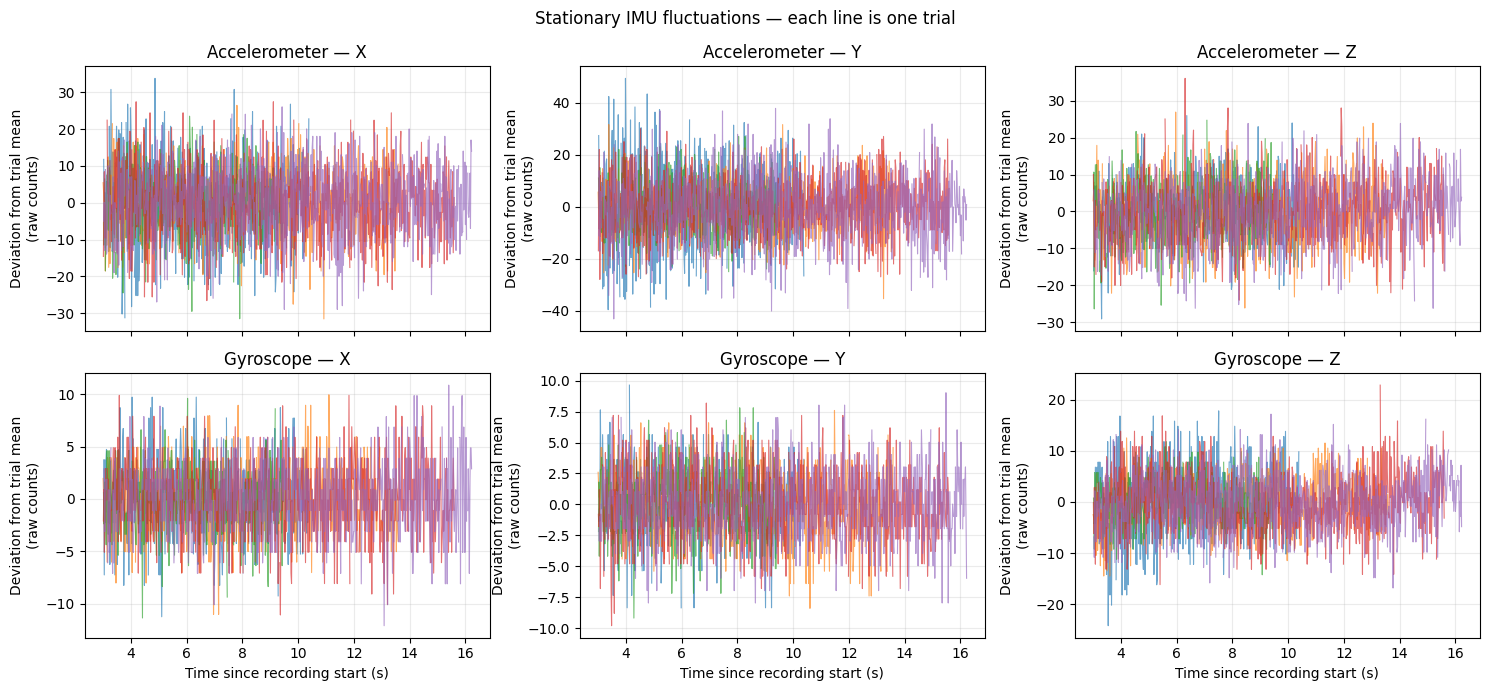

In [6]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Folder containing ONLY stationary trials collected in the same orientation.
FOLDER = Path("/Users/jadechng/Desktop/HomeStretch/HomeStretchRepo/Data/new_watch/stationary")

# Exclude the first few seconds of each trial to allow settling.
SETTLE_SECONDS = 3

SENSORS = {1: "Accelerometer", 2: "Gyroscope"}
AXES = {"x_raw": "X", "y_raw": "Y", "z_raw": "Z"}

files = sorted(FOLDER.glob("*.csv"))
if not files:
    raise ValueError(f"No CSV files found in: {FOLDER}")

trial_rows = []
quality_rows = []
traces = []

for file in files:
    df = pd.read_csv(file)

    required = {
        "protocol_session_id", "type", "watch_timestamp_ms",
        "validity", *AXES
    }
    if not required.issubset(df.columns):
        raise ValueError(f"Missing columns in {file.name}: {required - set(df.columns)}")

    for session_id, session in df.groupby("protocol_session_id", sort=False):
        trial = f"{file.stem} / {session_id}"
        session_start = pd.to_numeric(
            session["watch_timestamp_ms"], errors="raise"
        ).min()

        for sensor_type, sensor_name in SENSORS.items():
            data = session[session["type"] == sensor_type].copy()
            if data.empty:
                continue

            data["Time (s)"] = (
                pd.to_numeric(data["watch_timestamp_ms"], errors="raise")
                - session_start
            ) / 1000

            # Keep original order; reject bad timestamps rather than hiding them.
            t = data["Time (s)"].to_numpy()
            if not np.isfinite(t).all() or np.any(np.diff(t) <= 0):
                raise ValueError(f"Invalid timestamps: {trial}, {sensor_name}")

            data = data[data["Time (s)"] >= SETTLE_SECONDS].copy()
            if len(data) < 2:
                raise ValueError(f"Too little data after settling: {trial}")

            xyz = data[list(AXES)].apply(pd.to_numeric, errors="coerce")
            valid = (
                data["validity"].eq(1).to_numpy()
                & np.isfinite(xyz.to_numpy()).all(axis=1)
            )

            quality_rows.append({
                "Trial": trial,
                "Sensor": sensor_name,
                "Records after settling": len(data),
                "Excluded readings (%)": 100 * (1 - valid.mean()),
            })

            if valid.sum() < 2:
                raise ValueError(f"Too few valid readings: {trial}, {sensor_name}")

            for column, axis in AXES.items():
                values = xyz[column].to_numpy(dtype=float)
                good = values[valid]

                baseline = good.mean()
                residuals = good - baseline

                trial_rows.append({
                    "Trial": trial,
                    "Sensor": sensor_name,
                    "Axis": axis,
                    "Valid samples": len(good),
                    "Mean (raw counts)": baseline,
                    "Within-trial SD (raw counts)": good.std(ddof=1),
                    "RMS noise (raw counts)": np.sqrt(np.mean(residuals**2)),
                })

                # NaNs break the plot at invalid readings.
                plotted = values.copy()
                plotted[~valid] = np.nan
                traces.append({
                    "Trial": trial,
                    "Sensor": sensor_name,
                    "Axis": axis,
                    "Time": data["Time (s)"].to_numpy(),
                    "Residual": plotted - baseline,
                })

per_trial = pd.DataFrame(trial_rows)
quality = pd.DataFrame(quality_rows)

# Each trial gets equal weight in the across-trial summary.
summary_rows = []
for (sensor, axis), group in per_trial.groupby(["Sensor", "Axis"], sort=False):
    means = group["Mean (raw counts)"]

    summary_rows.append({
        "Sensor": sensor,
        "Axis": axis,
        "Trials": len(group),
        "Mean baseline (raw counts)": means.mean(),
        "Between-trial baseline SD (raw counts)": means.std(ddof=1),
        "Mean within-trial SD (raw counts)":
            group["Within-trial SD (raw counts)"].mean(),
        "Mean RMS noise (raw counts)":
            group["RMS noise (raw counts)"].mean(),
        "Max baseline difference (raw counts)":
            means.max() - means.min() if len(group) >= 2 else np.nan,
    })

consistency_summary = pd.DataFrame(summary_rows)

print("IMU SIGNAL CONSISTENCY — STATIONARY TRIALS")
display(consistency_summary.round(3))

print("\nINDIVIDUAL TRIAL RESULTS")
display(per_trial.round(3))

print("\nEXCLUDED READINGS — AFTER SETTLING")
display(quality.round(2))

if consistency_summary["Trials"].min() < 3:
    print("\nCollect at least 3 trials per sensor for a useful repeatability check.")

# Plot fluctuations around each trial's own mean.
fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharex=True)

for row, sensor in enumerate(SENSORS.values()):
    for col, axis in enumerate(AXES.values()):
        ax = axes[row, col]

        for trace in traces:
            if trace["Sensor"] == sensor and trace["Axis"] == axis:
                ax.plot(
                    trace["Time"], trace["Residual"],
                    alpha=0.65, linewidth=0.8
                )

        ax.set_title(f"{sensor} — {axis}")
        ax.set_ylabel("Deviation from trial mean\n(raw counts)")
        ax.grid(alpha=0.25)

        if row == 1:
            ax.set_xlabel("Time since recording start (s)")

fig.suptitle("Stationary IMU fluctuations — each line is one trial")
plt.tight_layout()
plt.show()